In [1]:
# BLOCK 1 (UPDATED): Environment - pinned to the working Kaggle versions (Python 3.13)
!pip install -q "opacus==1.6.0" "imbalanced-learn==0.14.2"

import importlib, json, sys
versions = {"python": sys.version.split()[0]}
for pkg in ["numpy", "sklearn", "imblearn", "torch", "pandas", "opacus"]:
    versions[pkg] = importlib.import_module(pkg).__version__
print(json.dumps(versions, indent=2))
json.dump(versions, open("env_versions.json", "w"), indent=2)

assert versions["numpy"].startswith("2.1"), "numpy version changed - check env"
assert versions["sklearn"].startswith("1.6"), "sklearn version changed - check env"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.9/308.9 kB 8.2 MB/s eta 0:00:00:00:01
{
  "python": "3.13.15",
  "numpy": "2.1.3",
  "sklearn": "1.6.1",
  "imblearn": "0.14.2",
  "torch": "2.11.0+cu128",
  "pandas": "2.3.3",
  "opacus": "1.6.0"
}


In [4]:
# BLOCK 2 (UPDATED): Imports - only what the pipeline actually uses
import os
import random
import warnings
from collections import deque

# Data manipulation
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Torch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, Subset

# Sklearn
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve, auc)

# Imbalanced-learn (what the resampling block actually uses)
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Warnings stay ON
warnings.simplefilter("default")
warnings.filterwarnings("ignore", category=DeprecationWarning, module="jupyter_client")

In [5]:
# BLOCK 3 (UPDATED): Device + reproducibility
print("GPU Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU detected")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

GPU Available: True
GPU Name: Tesla T4
Using device: cuda


In [ ]:
import glob
print(glob.glob("/kaggle/input/**/*.csv", recursive=True))

Shape: (461043, 45)

Columns: ['ts', 'src_ip', 'src_port', 'dst_ip', 'dst_port', 'proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice', 'label', 'type']

Missing values (total): 0

Class distribution:
 type
normal        300000
scanning       20000
dos            20000
injection      20000
ddos           20000
password       20000
xss            20000
ransomware     20000
backdoor       20000
mitm            1043
Name: count, dtype: int64

Normal: 65.1% | Attack: 34.9%


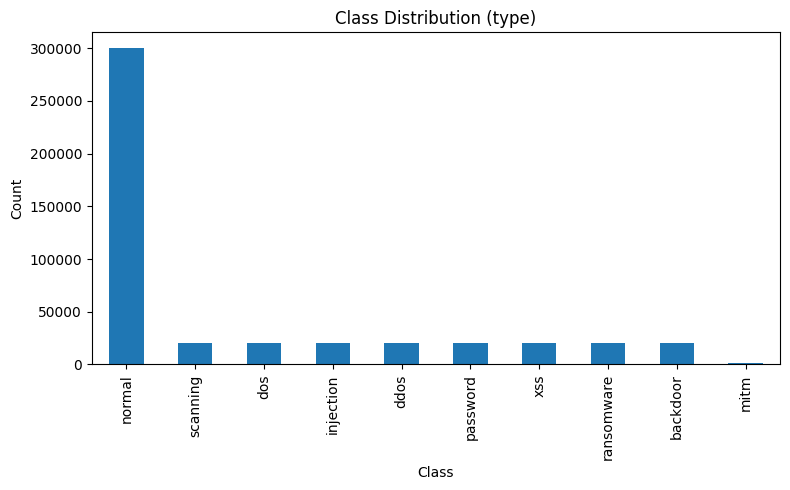

In [6]:
# BLOCK 4 (UPDATED): Load and explore the dataset
file_path = "/kaggle/input/datasets/fadiabuzwayed/ton-iot-train-test-network/TON_IoT_Train_Test_Network.csv"

if not os.path.exists(file_path):
    raise FileNotFoundError(f"Dataset not found at: {file_path}")

df = pd.read_csv(file_path)

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values (total):", int(df.isnull().sum().sum()))

# Class distribution - computed, not hardcoded
label_distribution = df['type'].value_counts()
print("\nClass distribution:\n", label_distribution)
normal_pct = 100 * (df['type'] == 'normal').mean()
print(f"\nNormal: {normal_pct:.1f}% | Attack: {100 - normal_pct:.1f}%")

plt.figure(figsize=(8, 5))
label_distribution.plot(kind='bar')
plt.title('Class Distribution (type)')
plt.xlabel('Class'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

In [7]:
# BLOCK 5 (UPDATED): Drop leak/shortcut columns, THEN remove duplicates
LEAK_COLUMNS     = ['label']                                          # binary copy of 'type'
SHORTCUT_COLUMNS = ['ts', 'src_ip', 'dst_ip', 'src_port', 'dst_port'] # identify the capture, not behaviour
df = df.drop(columns=LEAK_COLUMNS + SHORTCUT_COLUMNS)
assert 'label' not in df.columns

n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicates removed: {n0 - len(df)}")

# Conflicting rows: identical features but different class -> unlearnable, remove
feat_cols = [c for c in df.columns if c != 'type']
conflicts = df.duplicated(subset=feat_cols, keep=False)
print(f"Conflicting rows removed: {int(conflicts.sum())}")
df = df[~conflicts].reset_index(drop=True)

print(f"Final shape: {df.shape}")
print(df['type'].value_counts())

Exact duplicates removed: 271369
Conflicting rows removed: 629
Final shape: (189045, 39)
type
normal        119526
injection      19719
password       15167
ddos           11875
xss             8649
dos             6431
scanning        4476
backdoor        1965
mitm            1034
ransomware       203
Name: count, dtype: int64


# Upload and explore the dataset

In [8]:
# BLOCK 6 (UPDATED): Encode categorical columns + keep the TRUE class-name mapping
nominal = [c for c in df.columns if df[c].dtype == 'object' and c != 'type']
print("Categorical features:", nominal)
for col in nominal:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

type_encoder = LabelEncoder()
df['type'] = type_encoder.fit_transform(df['type'].astype(str))
class_names = list(type_encoder.classes_)          # use this everywhere for class names
print("Class mapping:", dict(enumerate(class_names)))

Categorical features: ['proto', 'service', 'conn_state', 'dns_query', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']
Class mapping: {0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


# Step 2: Segreggation *columns*

In [9]:
# BLOCK 7 (UPDATED): Split features/target + leakage checks
target_column = 'type'
X = df.drop(columns=[target_column])
y = df[target_column]

# Leakage guards
for c in ['type', 'label', 'ts', 'src_ip', 'dst_ip', 'src_port', 'dst_port']:
    assert c not in X.columns, f"Leakage guard: '{c}' still in features"
assert X.shape[1] == 38, f"Expected 38 features, got {X.shape[1]}"
assert X.shape[0] == y.shape[0]
assert int(X.isnull().sum().sum()) == 0 and int(y.isnull().sum()) == 0, "Missing values found"

print(f"Features: {X.shape} | Target: {y.shape}")
print("Feature columns:", X.columns.tolist())

Features: (189045, 38) | Target: (189045,)
Feature columns: ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']


In [10]:
# BLOCK 8 (UPDATED): Stratified 70/10/20 split + quantile transform fit on TRAIN only
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import QuantileTransformer

idx = np.arange(len(X))
train_idx, temp_idx = train_test_split(idx, test_size=0.30, stratify=y, random_state=SEED)
val_idx, test_idx   = train_test_split(temp_idx, test_size=2/3, stratify=y.iloc[temp_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))

# Quantile -> normal: handles heavy-tailed counts and label-encoded categoricals (fit on train only)
scaler = QuantileTransformer(n_quantiles=1000, output_distribution='normal',
                             subsample=200_000, random_state=SEED).fit(X.iloc[train_idx])

X_train = scaler.transform(X.iloc[train_idx]).astype(np.float32); y_train = y.iloc[train_idx].to_numpy()
X_val   = scaler.transform(X.iloc[val_idx]).astype(np.float32);   y_val   = y.iloc[val_idx].to_numpy()
X_test  = scaler.transform(X.iloc[test_idx]).astype(np.float32);  y_test  = y.iloc[test_idx].to_numpy()

train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
val_dataset   = TensorDataset(torch.from_numpy(X_val),   torch.from_numpy(y_val).long())
test_dataset  = TensorDataset(torch.from_numpy(X_test),  torch.from_numpy(y_test).long())

split_table = pd.DataFrame({
    'train': pd.Series(y_train).value_counts(),
    'val':   pd.Series(y_val).value_counts(),
    'test':  pd.Series(y_test).value_counts(),
}).sort_index()
split_table.index = [class_names[i] for i in split_table.index]
print(f"Train {len(y_train)} | Val {len(y_val)} | Test {len(y_test)}")
print(split_table)

Train 132331 | Val 18904 | Test 37810
            train    val   test
backdoor     1376    196    393
ddos         8312   1188   2375
dos          4502    643   1286
injection   13803   1972   3944
mitm          724    103    207
normal      83668  11952  23906
password    10617   1517   3033
ransomware    142     20     41
scanning     3133    448    895
xss          6054    865   1730


In [11]:
# BLOCK 8b (NEW): ExtraTrees feature selection - fitted on TRAIN only and actually applied
from sklearn.ensemble import ExtraTreesClassifier

TOP_K = 20
critical_security_features = [
    'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected',
    'ssl_cipher', 'ssl_established', 'ssl_issuer',
    'http_method', 'http_version', 'http_status_code',
    'http_request_body_len', 'http_resp_mime_types',
    'weird_name', 'weird_addl'
]

et = ExtraTreesClassifier(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
importance = pd.Series(et.feature_importances_, index=X.columns).sort_values(ascending=False)

keep = set(importance.head(TOP_K).index) | {f for f in critical_security_features if f in X.columns}
selected_features = [c for c in X.columns if c in keep]
sel_idx = [X.columns.get_loc(c) for c in selected_features]

X_train, X_val, X_test = X_train[:, sel_idx], X_val[:, sel_idx], X_test[:, sel_idx]
train_dataset = TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train).long())
val_dataset   = TensorDataset(torch.from_numpy(X_val),   torch.from_numpy(y_val).long())
test_dataset  = TensorDataset(torch.from_numpy(X_test),  torch.from_numpy(y_test).long())

print(f"Selected {len(selected_features)} features:", selected_features)
print("\nTop-20 importance:\n", importance.head(TOP_K))

Selected 29 features: ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_cipher', 'ssl_established', 'ssl_issuer', 'http_method', 'http_version', 'http_request_body_len', 'http_status_code', 'http_resp_mime_types', 'weird_name', 'weird_addl']

Top-20 importance:
 src_ip_bytes       0.152847
duration           0.123551
src_bytes          0.121241
dst_ip_bytes       0.092810
dst_bytes          0.089233
dst_pkts           0.070288
src_pkts           0.067252
conn_state         0.056940
proto              0.055411
dns_rejected       0.036994
service            0.032007
dns_RD             0.021955
dns_RA             0.014552
dns_AA             0.013337
dns_qclass         0.012625
dns_qtype          0.011550
dns_query          0.008983
missed_bytes       0.008048
dns_rcode          0.006085
ssl_es

In [12]:
# BLOCK 9 (UPDATED): Hybrid over/under-sampling on TRAIN only (capped) + class weights
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight

OVERSAMPLE_CAP = 10                                   # rare classes grow at most 10x
counts = Counter(y_train)
target = int(np.median(list(counts.values())))

over  = {c: min(target, n * OVERSAMPLE_CAP) for c, n in counts.items() if n < target}
under = {c: target for c, n in counts.items() if n > target}

X_res, y_res = RandomOverSampler(sampling_strategy=over, random_state=SEED).fit_resample(X_train, y_train)
X_res, y_res = RandomUnderSampler(sampling_strategy=under, random_state=SEED).fit_resample(X_res, y_res)

X_train_res, y_train_res = X_res.astype(np.float32), y_res.astype(np.int64)
balanced_train_ds = TensorDataset(torch.from_numpy(X_train_res), torch.from_numpy(y_train_res).long())

res_table = pd.DataFrame({'before': pd.Series(y_train).value_counts(),
                          'after':  pd.Series(y_train_res).value_counts()}).sort_index()
res_table.index = [class_names[i] for i in res_table.index]
print(f"Median target per class: {target}\n", res_table)

cw = compute_class_weight('balanced', classes=np.arange(len(class_names)), y=y_train_res)
class_weights = (np.sqrt(cw) / np.sqrt(cw).mean()).astype(np.float32)
for name, w in zip(class_names, class_weights):
    print(f"{name:12s} weight = {w:.3f}")

Median target per class: 5278
             before  after
backdoor      1376   5278
ddos          8312   5278
dos           4502   5278
injection    13803   5278
mitm           724   5278
normal       83668   5278
password     10617   5278
ransomware     142   1420
scanning      3133   5278
xss           6054   5278
backdoor     weight = 0.915
ddos         weight = 0.915
dos          weight = 0.915
injection    weight = 0.915
mitm         weight = 0.915
normal       weight = 0.915
password     weight = 0.915
ransomware   weight = 1.764
scanning     weight = 0.915
xss          weight = 0.915


In [13]:
# BLOCK 10 (UPDATED): Non-IID Dirichlet client split - seeded, no IID fallback
NUM_CLIENTS = 15
ALPHA = 2.0                     # Dirichlet concentration (lower = more non-IID)
MIN_PER_CLIENT = 100            # minimum total samples per client

def dirichlet_split(labels, num_clients, alpha, rng, min_per_client):
    num_classes = int(labels.max()) + 1
    for _ in range(100):
        client_idx = [[] for _ in range(num_clients)]
        for c in range(num_classes):
            idx_c = np.where(labels == c)[0]
            rng.shuffle(idx_c)
            p = rng.dirichlet([alpha] * num_clients)
            cuts = (np.cumsum(p) * len(idx_c)).astype(int)[:-1]
            for k, part in enumerate(np.split(idx_c, cuts)):
                client_idx[k].extend(part.tolist())
        if min(len(ci) for ci in client_idx) >= min_per_client:
            return [np.array(ci) for ci in client_idx]
    raise RuntimeError("Could not satisfy MIN_PER_CLIENT - lower it or raise ALPHA")

rng = np.random.default_rng(SEED)
client_indices = dirichlet_split(y_train_res, NUM_CLIENTS, ALPHA, rng, MIN_PER_CLIENT)

all_idx = np.concatenate(client_indices)
assert len(all_idx) == len(y_train_res) and len(np.unique(all_idx)) == len(y_train_res), "Overlap or missing samples"

clients_data = [Subset(balanced_train_ds, ci.tolist()) for ci in client_indices]
client_loaders = [DataLoader(cd, batch_size=32, shuffle=True,
                             generator=torch.Generator().manual_seed(SEED + k))
                  for k, cd in enumerate(clients_data)]
client_sample_sizes = [len(cd) for cd in clients_data]

client_table = pd.DataFrame(
    [np.bincount(y_train_res[ci], minlength=len(class_names)) for ci in client_indices],
    columns=class_names, index=[f"Client{k+1}" for k in range(NUM_CLIENTS)])
print(client_table)
print(f"\nSamples per client: min {min(client_sample_sizes)} | max {max(client_sample_sizes)}")

          backdoor  ddos  dos  injection  mitm  normal  password  ransomware  \
Client1        132   142  304        156   221     129         9          57   
Client2        332   190  588        213    58      82       141         165   
Client3        181   165   23         59   281     443       652         148   
Client4        431   669  842        427   120     363       711         178   
Client5         12   180  622        299   873     611       281         135   
Client6        388   283  181        764    99     223       138         157   
Client7        464   265  209        102   435     327       302         109   
Client8        270   700  158        987   160      93        64          81   
Client9        283   601  137        480   679     364       500         144   
Client10       244   462  277        464   172     336       457          32   
Client11       328   612  856        174   321     394       129          41   
Client12       951   477  149        230

In [14]:
# BLOCK 11 (UPDATED): IDS metrics, communication & privacy tracking
from typing import Iterable, Dict, List, Optional, Union
ArrayLike = Union[np.ndarray, torch.Tensor, List[float], List[int]]

def _to_np(x):
    return x.detach().cpu().numpy() if torch.is_tensor(x) else np.asarray(x)

# ---------- Multiclass + IDS metrics ----------
class MulticlassMetricsTracker:
    def __init__(self, num_classes: int, class_names: Optional[List[str]] = None, normal_class: str = 'normal'):
        self.num_classes = int(num_classes)
        self.class_names = class_names or [str(i) for i in range(self.num_classes)]
        assert len(self.class_names) == self.num_classes
        self.normal_idx = self.class_names.index(normal_class) if normal_class in self.class_names else None
        self.reset()

    def reset(self):
        self.cm = np.zeros((self.num_classes, self.num_classes), dtype=np.int64)   # rows = true, cols = pred
        self.metrics_history: Dict[int, List[Dict[str, float]]] = {i: [] for i in range(self.num_classes)}

    def update(self, predictions: ArrayLike, labels: ArrayLike):
        p = _to_np(predictions).astype(np.int64).ravel()
        t = _to_np(labels).astype(np.int64).ravel()
        assert p.shape == t.shape
        np.add.at(self.cm, (t, p), 1)

    def update_from_logits(self, logits: torch.Tensor, labels: ArrayLike):
        self.update(torch.argmax(logits, dim=1), labels)

    @property
    def TP(self): return np.diag(self.cm)
    @property
    def FP(self): return self.cm.sum(0) - np.diag(self.cm)
    @property
    def FN(self): return self.cm.sum(1) - np.diag(self.cm)
    @property
    def TN(self): return self.cm.sum() - self.TP - self.FP - self.FN

    def get_metrics(self, store_history: bool = True) -> Dict[str, Dict[str, float]]:
        res = {}
        TP, FP, FN, TN = self.TP, self.FP, self.FN, self.TN
        for c in range(self.num_classes):
            far = FP[c] / (FP[c] + TN[c]) if (FP[c] + TN[c]) else 0.0
            dr  = TP[c] / (TP[c] + FN[c]) if (TP[c] + FN[c]) else 0.0
            acc = (TP[c] + TN[c]) / self.cm.sum() if self.cm.sum() else 0.0
            m = {'FAR': float(far), 'DR': float(dr), 'Accuracy': float(acc), 'Support': int(self.cm[c].sum())}
            if store_history: self.metrics_history[c].append(m)
            res[self.class_names[c]] = m
        return res

    def ids_metrics(self) -> Dict[str, float]:
        """IDS view: FAR = normal flagged as attack; DR = attacks flagged as any attack."""
        assert self.normal_idx is not None, "normal class not found"
        n = self.normal_idx
        normal_total   = self.cm[n].sum()
        normal_as_att  = normal_total - self.cm[n, n]
        attack_rows    = [i for i in range(self.num_classes) if i != n]
        attack_total   = self.cm[attack_rows].sum()
        attack_as_att  = attack_total - self.cm[attack_rows, n].sum()
        return {'IDS_FAR': float(normal_as_att / normal_total) if normal_total else 0.0,
                'IDS_DR':  float(attack_as_att / attack_total) if attack_total else 0.0,
                'Accuracy': float(np.trace(self.cm) / self.cm.sum()) if self.cm.sum() else 0.0}

    def overall_metrics(self) -> Dict[str, float]:
        m = self.ids_metrics()
        return {'FAR': m['IDS_FAR'], 'DR': m['IDS_DR'], 'Accuracy': m['Accuracy']}

# ---------- Communication tracking ----------
class CommunicationTracker:
    def __init__(self):
        self.total_bytes, self.rounds = 0, 0
        self.bytes_history: List[int] = []; self.clients_history: List[int] = []; self.kind_history: List[str] = []

    @staticmethod
    def _nbytes_of(p): return int(_to_np(p).nbytes)

    def track_round(self, parameters, n_clients: int, kind: str = "delta"):
        b = sum(self._nbytes_of(p) for p in parameters)
        self.total_bytes += b; self.rounds += 1
        self.bytes_history.append(b); self.clients_history.append(int(n_clients)); self.kind_history.append(kind)

    def track_communication(self, parameters):
        self.track_round(parameters, n_clients=0, kind="unknown")
        return self.bytes_history[-1]

    def get_efficiency(self) -> Dict[str, float]:
        avg = self.total_bytes / self.rounds if self.rounds else 0.0
        return {'avg_bytes_per_round': avg, 'avg_MB_per_round': avg / 2**20,
                'total_MB': self.total_bytes / 2**20, 'rounds': self.rounds,
                'avg_clients_per_round': float(np.mean(self.clients_history)) if self.clients_history else 0.0}

    def reset(self): self.__init__()

# ---------- Privacy & utility tracking ----------
class PrivacyTracker:
    def __init__(self, delta: float = 1e-5, ldp: bool = True):
        self.delta, self.ldp = float(delta), bool(ldp)
        self.reset()

    def reset(self):
        self.round_index: List[int] = []; self.epsilon_history: List[float] = []
        self.sigma_history: List[float] = []; self.clip_history: List[float] = []
        self.grad_norm_history: List[float] = []; self.accuracy_history: List[float] = []
        self.epsilon_total_history: List[float] = []; self.dp_enabled_history: List[bool] = []

    def track_round(self, epsilon_t, sigma_t, clip_norm, grad_norm, accuracy, *,
                    eps_total=None, round_idx=None, dp_enabled=None):
        self.epsilon_history.append(float(epsilon_t)); self.sigma_history.append(float(sigma_t))
        self.clip_history.append(float(clip_norm)); self.grad_norm_history.append(float(grad_norm))
        self.accuracy_history.append(float(accuracy))
        self.epsilon_total_history.append(float(eps_total) if eps_total is not None else float('nan'))
        self.dp_enabled_history.append(bool(dp_enabled) if dp_enabled is not None else False)
        self.round_index.append(int(round_idx) if round_idx is not None else len(self.round_index) + 1)

    def get_privacy_utility_state(self, round_idx=None) -> Dict[str, float]:
        acc = self.accuracy_history[-1] if self.accuracy_history else 50.0
        g = float(np.mean(self.grad_norm_history[-5:])) if self.grad_norm_history else 1.0
        return {"avg_grad_norm": g, "recent_accuracy": float(acc)}

    def get_privacy_utility_snapshot(self, k: int = 5) -> Dict[str, float]:
        return {'current_round': self.round_index[-1] if self.round_index else 0,
                'epsilon_t': self.epsilon_history[-1] if self.epsilon_history else 0.0,
                'epsilon_total': self.epsilon_total_history[-1] if self.epsilon_total_history else 0.0,
                'delta': self.delta,
                'recent_accuracy': float(np.mean(self.accuracy_history[-k:])) if self.accuracy_history else 0.0,
                'avg_grad_norm': float(np.mean(self.grad_norm_history[-k:])) if self.grad_norm_history else 1.0,
                'ldp': self.ldp,
                'dp_enabled': self.dp_enabled_history[-1] if self.dp_enabled_history else False}

# Quick self-test
_t = MulticlassMetricsTracker(len(class_names), class_names)
_t.update(y_test[:1000], y_test[:1000])
print("Self-test (perfect preds):", _t.ids_metrics())

Self-test (perfect preds): {'IDS_FAR': 0.0, 'IDS_DR': 1.0, 'Accuracy': 1.0}


In [15]:
# BLOCK 12 (UPDATED): Real DDQN detector - trained ONLY with the DDQN (TD) loss
# MDP: state = flow features | action = predicted class | reward = +w[y] if correct, -w[y] if wrong
#      next state = next flow in the client's shuffled stream | episode = EPISODE_LEN flows
from typing import List, Iterable

class QNetwork(nn.Module):
    def __init__(self, input_dim: int, action_dim: int):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, 256), nn.LayerNorm(256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128),       nn.LayerNorm(128), nn.ReLU(), nn.Dropout(0.2),
        )
        self.q_head = nn.Linear(128, action_dim)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)

    def forward(self, x, mode: str = "q_value"):
        # 'mode' kept only for compatibility with later blocks - ALWAYS returns Q-values.
        return self.q_head(self.feature_extractor(x))


class TensorReplayBuffer:
    def __init__(self, capacity: int, state_dim: int, device):
        self.cap, self.device, self.ptr, self.size = int(capacity), device, 0, 0
        self.s  = torch.zeros(self.cap, state_dim, device=device)
        self.s2 = torch.zeros(self.cap, state_dim, device=device)
        self.a  = torch.zeros(self.cap, dtype=torch.long, device=device)
        self.r  = torch.zeros(self.cap, device=device)
        self.d  = torch.zeros(self.cap, device=device)

    def push_batch(self, s, a, r, s2, d):
        n = s.shape[0]
        idx = (torch.arange(n, device=self.device) + self.ptr) % self.cap
        self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.d[idx] = s, a, r, s2, d
        self.ptr = (self.ptr + n) % self.cap
        self.size = min(self.size + n, self.cap)

    def sample(self, n: int):
        idx = torch.randint(0, self.size, (n,), device=self.device)
        return self.s[idx], self.a[idx], self.r[idx], self.s2[idx], self.d[idx]

    def __len__(self): return self.size


class DDQN:
    def __init__(self, input_dim, action_dim, device, class_weights,
                 gamma=0.1, lr=1e-3, eps_start=1.0, eps_end=0.05, eps_decay_steps=2000,
                 buffer_capacity=50_000, batch_size=256, tau=0.005, episode_len=32):
        self.device, self.action_dim = device, action_dim
        self.gamma, self.batch_size, self.tau, self.episode_len = gamma, batch_size, tau, episode_len
        self.eps_start, self.eps_end, self.eps_decay_steps = eps_start, eps_end, eps_decay_steps
        self.steps = 0

        self.online_net = QNetwork(input_dim, action_dim).to(device)
        self.target_net = QNetwork(input_dim, action_dim).to(device)
        self.target_net.load_state_dict(self.online_net.state_dict()); self.target_net.eval()
        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)
        self.loss_fn = nn.SmoothL1Loss()

        self.reward_w = torch.tensor(class_weights, dtype=torch.float32, device=device)
        self.memory = TensorReplayBuffer(buffer_capacity, input_dim, device)

    @property
    def epsilon(self):
        frac = min(1.0, self.steps / self.eps_decay_steps)
        return self.eps_start + frac * (self.eps_end - self.eps_start)

    @torch.no_grad()
    def act(self, states):
        self.online_net.eval()
        greedy = self.online_net(states).argmax(1)
        self.online_net.train()
        rand = torch.randint(0, self.action_dim, greedy.shape, device=self.device)
        explore = torch.rand(greedy.shape, device=self.device) < self.epsilon
        return torch.where(explore, rand, greedy)

    def reward(self, actions, labels):
        w = self.reward_w[labels]
        return torch.where(actions == labels, w, -w)

    @torch.no_grad()
    def collect(self, xb, yb):
        xb, yb = xb.to(self.device), yb.to(self.device)
        actions = self.act(xb)
        rewards = self.reward(actions, yb)
        next_states = torch.roll(xb, shifts=-1, dims=0)
        dones = ((torch.arange(len(xb), device=self.device) + 1) % self.episode_len == 0).float()
        dones[-1] = 1.0
        self.memory.push_batch(xb, actions, rewards, next_states, dones)
        return actions

    def td_loss(self):
        if len(self.memory) < self.batch_size:
            return None
        s, a, r, s2, d = self.memory.sample(self.batch_size)
        q = self.online_net(s).gather(1, a.unsqueeze(1)).squeeze(1)
        with torch.no_grad():
            self.online_net.eval()
            best_next = self.online_net(s2).argmax(1, keepdim=True)          # online selects
            self.online_net.train()
            next_q = self.target_net(s2).gather(1, best_next).squeeze(1)    # target evaluates
            target = r + (1.0 - d) * self.gamma * next_q
        return self.loss_fn(q, target)

    def train_step(self, extra_loss=None, max_grad_norm=1.0):
        loss = self.td_loss()
        if loss is None:
            return None
        total = loss + (extra_loss() if extra_loss is not None else 0.0)
        self.optimizer.zero_grad(set_to_none=True)
        total.backward()
        torch.nn.utils.clip_grad_norm_(self.online_net.parameters(), max_grad_norm)
        self.optimizer.step()
        self.update_target()
        self.steps += 1
        return float(loss.item())

    @torch.no_grad()
    def update_target(self):
        for tp, p in zip(self.target_net.parameters(), self.online_net.parameters()):
            tp.data.lerp_(p.data, self.tau)

    @torch.no_grad()
    def predict(self, x):
        self.online_net.eval()
        out = self.online_net(x.to(self.device)).argmax(1)
        self.online_net.train()
        return out

    def get_fl_parameters(self) -> List[torch.Tensor]:
        return [p.detach().cpu().clone() for p in self.online_net.parameters()]

    @torch.no_grad()
    def set_fl_parameters(self, params: Iterable[torch.Tensor]):
        for p, new in zip(self.online_net.parameters(), params):
            p.data.copy_(new.to(p.device))
        self.target_net.load_state_dict(self.online_net.state_dict())

    @torch.no_grad()
    def param_vector(self):
        return torch.cat([p.detach().view(-1) for p in self.online_net.parameters()])


# ---------- Smoke test: does a single agent learn from reward alone? ----------
input_dim, action_dim = X_train.shape[1], len(class_names)
_agent = DDQN(input_dim, action_dim, device, class_weights, eps_decay_steps=500)
print("Input features:", input_dim, "| Parameters:", sum(p.numel() for p in _agent.online_net.parameters()))

for ep in range(10):
    losses = []
    for xb, yb in client_loaders[0]:
        _agent.collect(xb, yb)
        l = _agent.train_step()
        if l is not None: losses.append(l)
    print(f"epoch {ep+1:2d}: steps={_agent.steps:4d} eps={_agent.epsilon:.3f} "
          f"TD-loss={np.mean(losses) if losses else float('nan'):.4f}")

_m = MulticlassMetricsTracker(action_dim, class_names)
for xb, yb in DataLoader(val_dataset, batch_size=1024):
    _m.update(_agent.predict(xb), yb)
print("\nVal (single client, reward-only):", _m.ids_metrics())
for name, m in _m.get_metrics(store_history=False).items():
    print(f"{name:12s} DR={m['DR']:.3f}  support={m['Support']}")
del _agent, _m

Input features: 29 | Parameters: 42634
epoch  1: steps=  51 eps=0.903 TD-loss=0.2609
epoch  2: steps= 109 eps=0.793 TD-loss=0.1818
epoch  3: steps= 167 eps=0.683 TD-loss=0.1771
epoch  4: steps= 225 eps=0.573 TD-loss=0.1655
epoch  5: steps= 283 eps=0.462 TD-loss=0.1560
epoch  6: steps= 341 eps=0.352 TD-loss=0.1448
epoch  7: steps= 399 eps=0.242 TD-loss=0.1426
epoch  8: steps= 457 eps=0.132 TD-loss=0.1363
epoch  9: steps= 515 eps=0.050 TD-loss=0.1377
epoch 10: steps= 573 eps=0.050 TD-loss=0.1428

Val (single client, reward-only): {'IDS_FAR': 0.3811914323962517, 'IDS_DR': 0.997698504027618, 'Accuracy': 0.6165890816758358}
backdoor     DR=0.000  support=196
ddos         DR=0.664  support=1188
dos          DR=0.785  support=643
injection    DR=0.886  support=1972
mitm         DR=0.883  support=103
normal       DR=0.619  support=11952
password     DR=0.000  support=1517
ransomware   DR=1.000  support=20
scanning     DR=0.933  support=448
xss          DR=0.797  support=865


In [16]:
# BLOCK 13 (UPDATED): FL client - DDQN local training (reward only) + FedProx + client-level DP on Δ
import math

DP_ENABLED = False   # Run 1: non-private FL baseline. Privacy results may ONLY come from runs with True.

class FLClient:
    def __init__(self, ddqn, train_loader, device, model_name="Client",
                 default_mu=0.01, default_epsilon=1.0, default_clip_norm=1.0,
                 default_delta=1e-5, updates_per_batch=2):
        self.ddqn, self.train_loader = ddqn, train_loader
        self.device, self.model_name = torch.device(device), model_name
        self.mu, self.epsilon = float(default_mu), float(default_epsilon)
        self.clip_norm, self.delta = float(default_clip_norm), float(default_delta)
        self.updates_per_batch = int(updates_per_batch)
        self.global_params = None
        self.last_signal_norm = self.last_noise_norm = 0.0

    def set_parameters(self, parameters): self.ddqn.set_fl_parameters(parameters)
    def get_parameters(self): return self.ddqn.get_fl_parameters()

    # Standard FedProx: (mu/2) * SUM ||w - w_global||^2  (no division by #params)
    def _prox_term(self):
        snap = [g.to(self.device) for g in self.global_params]
        params = list(self.ddqn.online_net.parameters())
        def prox():
            return 0.5 * self.mu * sum(torch.sum((p - g) ** 2) for p, g in zip(params, snap))
        return prox

    def local_train(self, epochs):
        prox = self._prox_term() if (self.global_params is not None and self.mu > 0) else None
        losses = []
        for _ in range(max(1, int(epochs))):
            for xb, yb in self.train_loader:
                self.ddqn.collect(xb, yb)
                for _ in range(self.updates_per_batch):
                    l = self.ddqn.train_step(extra_loss=prox)
                    if l is not None: losses.append(l)
        return float(np.mean(losses)) if losses else float('nan')

    @torch.no_grad()
    def local_accuracy(self, max_samples=2048):
        correct = total = 0
        for xb, yb in self.train_loader:
            correct += int((self.ddqn.predict(xb).cpu() == yb).sum()); total += len(yb)
            if total >= max_samples: break
        return 100.0 * correct / max(1, total)

    def fit(self, parameters, config):
        self.set_parameters(parameters)
        self.global_params = [p.detach().cpu().clone() for p in self.ddqn.online_net.parameters()]
        self.epsilon   = float(config.get("epsilon",   self.epsilon))
        self.clip_norm = float(config.get("clip_norm", self.clip_norm))
        self.delta     = float(config.get("delta",     self.delta))
        self.mu        = float(config.get("mu",        self.mu))

        td_loss = self.local_train(int(config.get("local_epochs", 1)))

        with torch.no_grad():
            g_vec = torch.cat([g.view(-1) for g in self.global_params]).to(self.device)
            delta_vec = self.ddqn.param_vector() - g_vec
            delta_l2_raw = float(torch.norm(delta_vec))
            C = self.clip_norm
            sigma = C * math.sqrt(2 * math.log(1.25 / self.delta)) / max(self.epsilon, 1e-12)

            if DP_ENABLED:
                delta_clipped = delta_vec * min(1.0, C / (delta_l2_raw + 1e-12))
                noise = torch.normal(0.0, sigma, size=delta_clipped.shape, device=self.device)
                delta_private = delta_clipped + noise
                assert float(torch.norm(noise)) > 0, "DP guard: noise not applied"
            else:
                delta_clipped = delta_vec                       # non-private baseline: no clip, no noise
                noise = torch.zeros_like(delta_vec)
                delta_private = delta_vec

            self.last_signal_norm = float(torch.norm(delta_clipped))
            self.last_noise_norm  = float(torch.norm(noise))

            new_params, off = [], 0
            for g in self.global_params:
                n = g.numel()
                new_params.append((g.to(self.device) + delta_private[off:off + n].view_as(g)).cpu())
                off += n

        metrics = {
            "loss": td_loss, "accuracy": self.local_accuracy(),
            "grad_sensitivity": delta_l2_raw, "delta_l2": delta_l2_raw,
            "epsilon": self.epsilon, "sigma": sigma if DP_ENABLED else 0.0,
            "clip_norm": C, "mu": self.mu, "dp_enabled": DP_ENABLED,
            "signal_norm": self.last_signal_norm, "noise_norm": self.last_noise_norm,
        }
        return new_params, len(self.train_loader.dataset), metrics


# ---------- Smoke test: one local round on 2 clients ----------
_global = DDQN(input_dim, action_dim, device, class_weights)
_P = sum(p.numel() for p in _global.online_net.parameters())
for k in range(2):
    c = FLClient(DDQN(input_dim, action_dim, device, class_weights), client_loaders[k], device, model_name=f"Client{k+1}")
    _, n, m = c.fit(_global.get_fl_parameters(), {"local_epochs": 1, "mu": 0.01, "epsilon": 1.0, "clip_norm": 1.0})
    print(f"{c.model_name}: n={n} | TD-loss={m['loss']:.4f} | local acc={m['accuracy']:.1f}% | ‖Δ‖={m['delta_l2']:.3f} | DP={m['dp_enabled']}")

_sigma = 1.0 * math.sqrt(2 * math.log(1.25 / 1e-5)) / 1.0
print(f"\nIf DP were ON (eps=1, C=1): sigma={_sigma:.2f} -> expected noise norm ≈ {_sigma * math.sqrt(_P):.0f} vs signal ≤ 1.0")
del _global, c

Client1: n=1830 | TD-loss=0.2415 | local acc=38.4% | ‖Δ‖=2.163 | DP=False
Client2: n=2732 | TD-loss=0.2016 | local acc=46.6% | ‖Δ‖=2.340 | DP=False

If DP were ON (eps=1, C=1): sigma=4.84 -> expected noise norm ≈ 1000 vs signal ≤ 1.0


# ExtraTree Feature Selection

In [18]:
# BLOCK 14 (UPDATED): Server - aggregation, evaluation, one FL round (no client trimming)
import math

@torch.no_grad()
def evaluate_global(global_ddqn, dataset, batch_size=1024):
    m = MulticlassMetricsTracker(len(class_names), class_names)
    for xb, yb in DataLoader(dataset, batch_size=batch_size):
        m.update(global_ddqn.predict(xb), yb)
    return m

def weighted_average(client_params, client_sizes):
    total = float(sum(client_sizes))
    return [sum((n / total) * p[i] for p, n in zip(client_params, client_sizes))
            for i in range(len(client_params[0]))]

def federated_round(round_idx, global_ddqn, clients, rng, *, client_fraction, local_epochs,
                    mu, epsilon, clip_norm, delta, privacy_tracker=None, comm_tracker=None):
    k = max(1, math.ceil(client_fraction * len(clients)))
    active = rng.choice(len(clients), size=k, replace=False)
    global_params = global_ddqn.get_fl_parameters()

    params, sizes, mets = [], [], []
    for i in active:
        p, n, m = clients[i].fit(global_params, {"local_epochs": local_epochs, "mu": mu,
                                                 "epsilon": epsilon, "clip_norm": clip_norm, "delta": delta})
        params.append(p); sizes.append(n); mets.append(m)

    global_ddqn.set_fl_parameters(weighted_average(params, sizes))

    if comm_tracker is not None:
        comm_tracker.track_round([t for p in params for t in p], n_clients=k, kind="uplink")

    val = evaluate_global(global_ddqn, val_dataset).ids_metrics()
    med_delta = float(np.median([m["delta_l2"] for m in mets]))
    if privacy_tracker is not None:
        privacy_tracker.track_round(
            epsilon if DP_ENABLED else 0.0,
            float(np.mean([m["sigma"] for m in mets])),
            clip_norm, med_delta, 100.0 * val["Accuracy"],
            round_idx=round_idx, dp_enabled=DP_ENABLED)

    print(f"Round {round_idx:02d} | clients={k} | Acc={100*val['Accuracy']:.2f}% | "
          f"FAR={100*val['IDS_FAR']:.2f}% | DR={100*val['IDS_DR']:.2f}% | "
          f"med‖Δ‖={med_delta:.3f} | ‖noise‖={np.mean([m['noise_norm'] for m in mets]):.1f} | DP={DP_ENABLED}")
    return val, mets

In [19]:
# BLOCK 15 (UPDATED): Final evaluation & plots - correct class names, Q-values as scores
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.preprocessing import label_binarize

@torch.no_grad()
def collect_predictions(global_ddqn, dataset, batch_size=1024):
    net = global_ddqn.online_net; net.eval()
    qs, ys = [], []
    for xb, yb in DataLoader(dataset, batch_size=batch_size):
        qs.append(net(xb.to(device)).cpu()); ys.append(yb)
    net.train()
    q = torch.cat(qs).numpy(); y_true = torch.cat(ys).numpy()
    return y_true, q.argmax(1), q

def final_report(global_ddqn, dataset, title="Test"):
    y_true, y_pred, q = collect_predictions(global_ddqn, dataset)
    m = MulticlassMetricsTracker(len(class_names), class_names); m.update(y_pred, y_true)
    ids = m.ids_metrics()
    print(f"\n===== {title} =====")
    print(f"Accuracy={100*ids['Accuracy']:.2f}% | IDS_FAR={100*ids['IDS_FAR']:.2f}% | IDS_DR={100*ids['IDS_DR']:.2f}%")
    print(classification_report(y_true, y_pred, labels=list(range(len(class_names))),
                                target_names=class_names, digits=3, zero_division=0))
    # One-vs-rest AUC using Q-values as ranking scores (Q-values are not probabilities)
    y_bin = label_binarize(y_true, classes=list(range(len(class_names))))
    aucs = {class_names[i]: float(roc_auc_score(y_bin[:, i], q[:, i]))
            for i in range(len(class_names)) if y_bin[:, i].any()}
    print("OvR AUC (Q-value scores):", {k: round(v, 4) for k, v in aucs.items()})
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted'); plt.ylabel('True'); plt.title(f'Confusion matrix - {title}')
    plt.tight_layout(); plt.show()
    return {"ids": ids, "auc": aucs, "cm": cm}

def plot_training_curves(history):
    r = [h['round'] for h in history]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(r, [100 * h['Accuracy'] for h in history]); ax[0].set_title('Validation accuracy (%)'); ax[0].set_xlabel('Round')
    ax[1].plot(r, [100 * h['IDS_FAR'] for h in history], label='FAR')
    ax[1].plot(r, [100 * h['IDS_DR'] for h in history], label='DR')
    ax[1].set_title('IDS FAR / DR (%)'); ax[1].set_xlabel('Round'); ax[1].legend()
    plt.tight_layout(); plt.show()

In [20]:
# BLOCK 16 (UPDATED - Chapter 6): Record-level DP-SGD client + RDP privacy accounting
# - Each flow (record) is used by ONE client, ONCE (all training data, no oversampling copies) -> clean record-level DP
# - Per-sample gradients clipped to C, Gaussian noise N(0, (sigma*C)^2), Poisson sampling
# - Privacy measured with Opacus RDP accountant (no hand formula)
# - DP runs use one-step targets (gamma = 0): each loss term depends on one record only.
#   Justified by the gamma ablation (gamma 0.1 vs 0 gave the same accuracy).
import math
import torch.nn.functional as F
from torch.func import functional_call, vmap, grad
from opacus.accountants import RDPAccountant
from sklearn.utils.class_weight import compute_class_weight

# ---------- DP data: ALL training records, each in exactly one client (no under/oversampling) ----------
# Suggestion #1: more records per client -> smaller sampling rate q -> less noise for the same epsilon.
# Class imbalance is handled by the DDQN reward weights (square-root balanced).
X_dp, y_dp = X_train.astype(np.float32), y_train.astype(np.int64)
cw_dp = compute_class_weight('balanced', classes=np.arange(len(class_names)), y=y_dp)
class_weights_dp = (np.sqrt(cw_dp) / np.sqrt(cw_dp).mean()).astype(np.float32)

dp_client_indices = dirichlet_split(y_dp, NUM_CLIENTS, ALPHA, np.random.default_rng(SEED), MIN_PER_CLIENT)
_all = np.concatenate(dp_client_indices)
assert len(_all) == len(y_dp) and len(np.unique(_all)) == len(y_dp), "A record is in more than one client"
print("DP class weights:", dict(zip(class_names, np.round(class_weights_dp, 3))))
print("DP training data per class:", dict(zip(class_names, np.bincount(y_dp, minlength=len(class_names)))))
print("DP client sizes:", [len(ci) for ci in dp_client_indices])


class DPClient:
    def __init__(self, ddqn, X_local, y_local, device, model_name="Client",
                 batch_size=64, clip_norm=1.0, delta=1e-5):
        self.ddqn, self.device, self.model_name = ddqn, device, model_name
        self.X = torch.as_tensor(X_local, dtype=torch.float32, device=device)
        self.y = torch.as_tensor(y_local, dtype=torch.long, device=device)
        self.n = len(self.y)
        self.batch_size, self.C, self.delta = batch_size, float(clip_norm), float(delta)
        self.q = batch_size / self.n                       # Poisson sampling rate
        self.accountant = RDPAccountant()
        self.mu, self.global_params = 0.0, None

    def epsilon_spent(self):
        return float(self.accountant.get_epsilon(delta=self.delta)) if self.accountant.history else 0.0

    def _dp_step(self, sigma):
        net = self.ddqn.online_net
        idx = (torch.rand(self.n, device=self.device) < self.q).nonzero().squeeze(1)
        self.accountant.step(noise_multiplier=sigma, sample_rate=self.q)   # counted even if batch is empty

        params  = {k: v.detach() for k, v in net.named_parameters()}
        buffers = {k: v.detach() for k, v in net.named_buffers()}

        if len(idx) > 0:
            x, y = self.X[idx], self.y[idx]
            a = self.ddqn.act(x)                          # epsilon-greedy action
            r = self.ddqn.reward(a, y)                    # one-step target (gamma = 0)
            net.train()

            def loss_fn(p, b, xi, ai, ri):
                qv = functional_call(net, (p, b), (xi.unsqueeze(0),)).squeeze(0)
                return F.smooth_l1_loss(qv.gather(0, ai.unsqueeze(0)).squeeze(0), ri)

            g = vmap(grad(loss_fn), in_dims=(None, None, 0, 0, 0), randomness="different")(params, buffers, x, a, r)
            B = len(idx)
            norms = torch.sqrt(sum(gi.reshape(B, -1).pow(2).sum(1) for gi in g.values()))
            factor = (self.C / (norms + 1e-12)).clamp(max=1.0)            # per-sample clipping
            summed = {k: (gi * factor.view(-1, *([1] * (gi.dim() - 1)))).sum(0) for k, gi in g.items()}
        else:
            summed = {k: torch.zeros_like(v) for k, v in params.items()}

        expected_bs = self.q * self.n
        for k, p in net.named_parameters():
            noise = torch.normal(0.0, sigma * self.C, size=p.shape, device=self.device)
            p.grad = (summed[k] + noise) / expected_bs
            if self.global_params is not None and self.mu > 0:          # FedProx: data-independent, no privacy cost
                p.grad = p.grad + self.mu * (p.detach() - self.global_params[k])
        self.ddqn.optimizer.step()
        self.ddqn.optimizer.zero_grad(set_to_none=True)
        self.ddqn.update_target()
        self.ddqn.steps += 1

    @torch.no_grad()
    def local_accuracy(self, max_samples=2048):
        xs, ys = self.X[:max_samples], self.y[:max_samples]
        return 100.0 * float((self.ddqn.predict(xs) == ys).float().mean())

    def fit(self, parameters, config):
        self.ddqn.set_fl_parameters(parameters)
        net = self.ddqn.online_net
        self.global_params = {k: v.detach().clone() for k, v in net.named_parameters()}
        self.mu = float(config.get("mu", 0.0))
        sigma = float(config["noise_multiplier"])
        for _ in range(int(config["local_steps"])):
            self._dp_step(sigma)
        # Aggregation of a DP-trained model is post-processing: no extra noise needed here
        metrics = {"accuracy": self.local_accuracy(), "sigma": sigma,
                   "epsilon_spent": self.epsilon_spent(), "dp_enabled": True,
                   "delta_l2": float(torch.norm(self.ddqn.param_vector() -
                                     torch.cat([v.view(-1) for v in self.global_params.values()]))),
                   "noise_norm": 0.0}
        return self.ddqn.get_fl_parameters(), self.n, metrics

DP class weights: {'backdoor': np.float32(1.191), 'ddos': np.float32(0.485), 'dos': np.float32(0.659), 'injection': np.float32(0.376), 'mitm': np.float32(1.642), 'normal': np.float32(0.153), 'password': np.float32(0.429), 'ransomware': np.float32(3.708), 'scanning': np.float32(0.789), 'xss': np.float32(0.568)}
DP training data per class: {'backdoor': np.int64(1376), 'ddos': np.int64(8312), 'dos': np.int64(4502), 'injection': np.int64(13803), 'mitm': np.int64(724), 'normal': np.int64(83668), 'password': np.int64(10617), 'ransomware': np.int64(142), 'scanning': np.int64(3133), 'xss': np.int64(6054)}
DP client sizes: [7256, 7891, 13440, 16112, 6818, 3499, 7084, 8926, 12627, 14953, 8986, 4299, 8225, 5854, 6361]


In [27]:
# BLOCK 17 (NEW - Chapter 6): ADP-Meta controller - REINFORCE policy over noise levels
# state  s_t = [t/T, Acc_{t-1}, dAcc_{t-1}, eps_spent / eps_budget]
# action a_t = noise multiplier from LEVEL_MULTS (larger = more noise = more privacy)
# reward r_t = dAcc_t - LAMBDA * (eps_t - eps_{t-1}) / eps_budget
# update: REINFORCE with moving-average baseline + entropy bonus
class ADPMetaController(nn.Module):
    def __init__(self, sigma_levels, state_dim=4, lr=1e-2, baseline_beta=0.9, entropy_coef=0.01, device="cpu"):
        super().__init__()
        self.sigma_levels = list(sigma_levels)
        self.device = torch.device(device)
        self.policy = nn.Sequential(nn.Linear(state_dim, 32), nn.Tanh(),
                                    nn.Linear(32, len(self.sigma_levels))).to(self.device)
        self.opt = optim.Adam(self.policy.parameters(), lr=lr)
        self.baseline, self.beta, self.entropy_coef = 0.0, baseline_beta, entropy_coef
        self._log_prob = self._entropy = None
        self.history = []                                   # (round, state, action, level, reward)

    def select(self, state):
        s = torch.as_tensor(state, dtype=torch.float32, device=self.device)
        dist = torch.distributions.Categorical(logits=self.policy(s))
        a = dist.sample()
        self._log_prob, self._entropy = dist.log_prob(a), dist.entropy()
        self._last = (list(map(float, state)), int(a))
        return int(a), self.sigma_levels[int(a)]

    def update(self, reward, round_idx):
        adv = float(reward) - self.baseline
        loss = -adv * self._log_prob - self.entropy_coef * self._entropy
        self.opt.zero_grad(); loss.backward(); self.opt.step()
        self.baseline = self.beta * self.baseline + (1 - self.beta) * float(reward)
        s, a = self._last
        self.history.append({"round": round_idx, "state": s, "action": a,
                             "sigma": self.sigma_levels[a], "reward": float(reward)})

Run: fedprox_adpmeta_recordDP_eps8.0 | 20 rounds | 15 clients/round x1.0 | FedProx mu=0.01
DP=record-level | clip C=7.831 | base sigma: median 1.992
Round 01 | mult=0.80 | eps=2.878/8.0 | VAL Acc=47.97% P=19.1 R=18.1 F1=16.8 | FAR=35.31% DR=52.47%
          per-attack F1: backdoor=0 | ddos=44 | dos=23 | injection=32 | mitm=0 | normal=67 | password=1 | ransomware=0 | scanning=0 | xss=1
Round 02 | mult=0.80 | eps=3.765/8.0 | VAL Acc=64.69% P=22.9 R=25.7 F1=22.4 | FAR=17.00% DR=73.45%
          per-attack F1: backdoor=0 | ddos=56 | dos=26 | injection=43 | mitm=0 | normal=84 | password=1 | ransomware=0 | scanning=0 | xss=14
Round 03 | mult=1.50 | eps=3.873/8.0 | VAL Acc=65.25% P=21.9 R=22.7 F1=21.0 | FAR=11.05% DR=55.94%
          per-attack F1: backdoor=0 | ddos=52 | dos=19 | injection=34 | mitm=0 | normal=83 | password=1 | ransomware=0 | scanning=0 | xss=20
Round 04 | mult=1.20 | eps=4.063/8.0 | VAL Acc=68.24% P=25.0 R=24.7 F1=22.5 | FAR=8.02% DR=57.85%
          per-attack F1: backdoor=

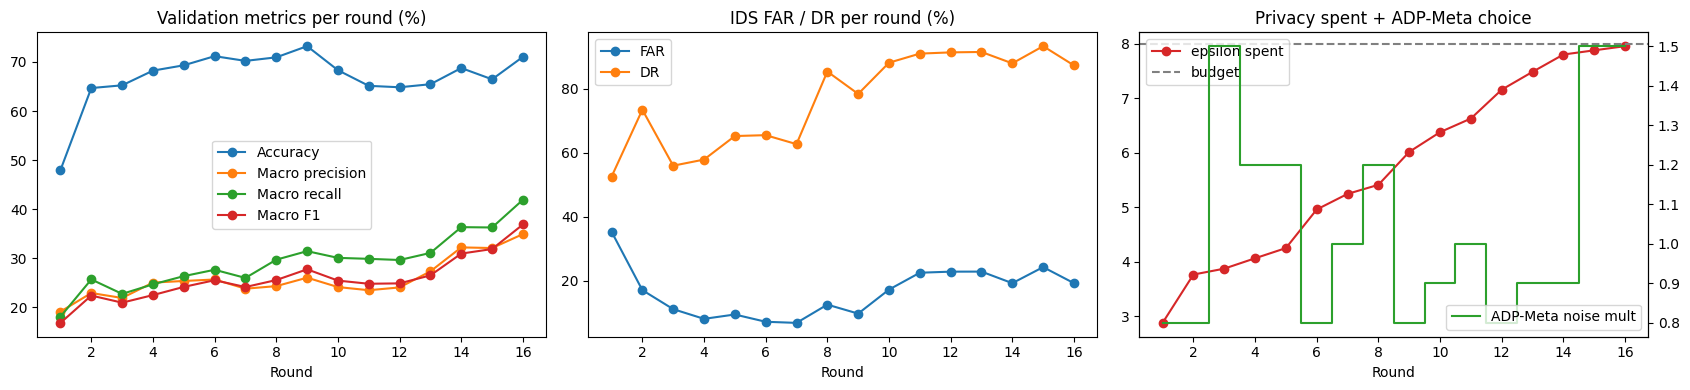

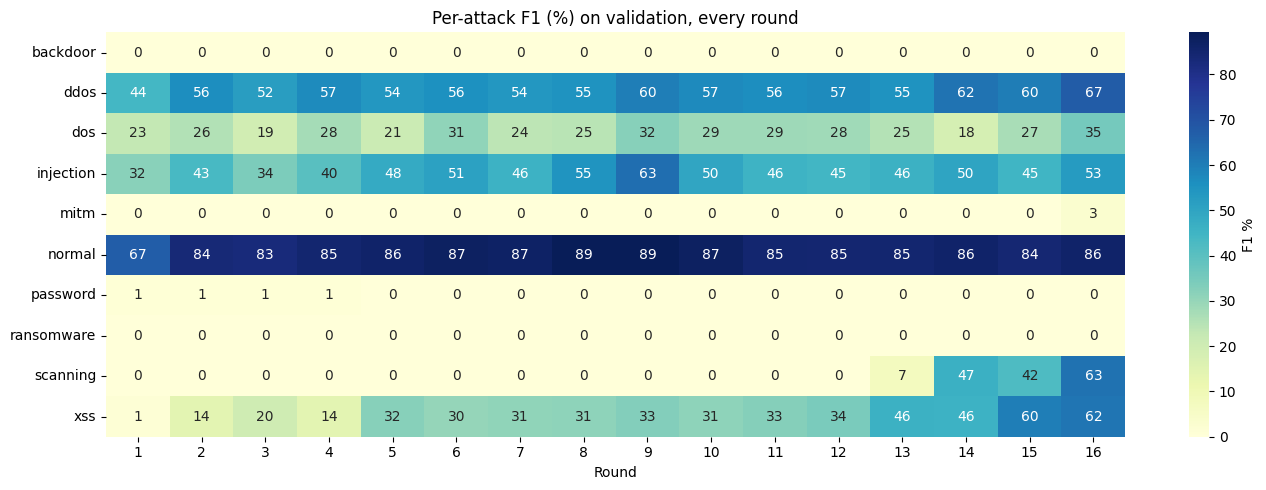


Best validation round: 9 (VAL Acc=73.22%)

===== TEST - fedprox_adpmeta_recordDP_eps8.0 =====
Accuracy=73.17% | IDS_FAR=10.19% | IDS_DR=78.00%
              precision    recall  f1-score   support

    backdoor      0.000     0.000     0.000       393
        ddos      0.496     0.763     0.601      2375
         dos      0.276     0.336     0.303      1286
   injection      0.510     0.860     0.640      3944
        mitm      0.000     0.000     0.000       207
      normal      0.875     0.898     0.887     23906
    password      0.023     0.001     0.001      3033
  ransomware      0.000     0.000     0.000        41
    scanning      0.000     0.000     0.000       895
         xss      0.458     0.321     0.378      1730

    accuracy                          0.732     37810
   macro avg      0.264     0.318     0.281     37810
weighted avg      0.670     0.732     0.693     37810

OvR AUC (Q-value scores): {'backdoor': 0.1024, 'ddos': 0.854, 'dos': 0.8192, 'injection': 0.8929,

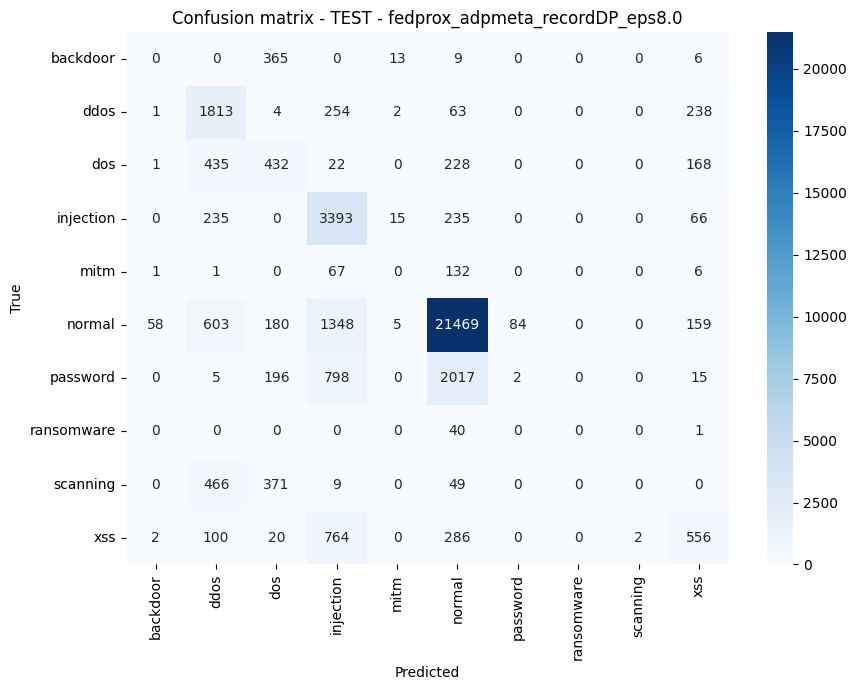


FINAL TEST RESULT
 Model              FedProx + DDQN + ADP-Meta
DP                              record-level
Rounds                                    16
Clients/round                             15
Accuracy %                             73.17
Macro Precision %                      26.37
Macro Recall %                          31.8
Macro F1 %                             28.09
Weighted F1 %                          69.27
FAR %                                  10.19
DR %                                    78.0
epsilon                                7.956
delta                                0.00001

PER-ATTACK TEST RESULT
             Precision %  Recall %   F1 %  Support
backdoor           0.00      0.00   0.00      393
ddos              49.56     76.34  60.10     2375
dos               27.55     33.59  30.27     1286
injection         50.98     86.03  64.02     3944
mitm               0.00      0.00   0.00      207
normal            87.53     89.81  88.65    23906
password           2

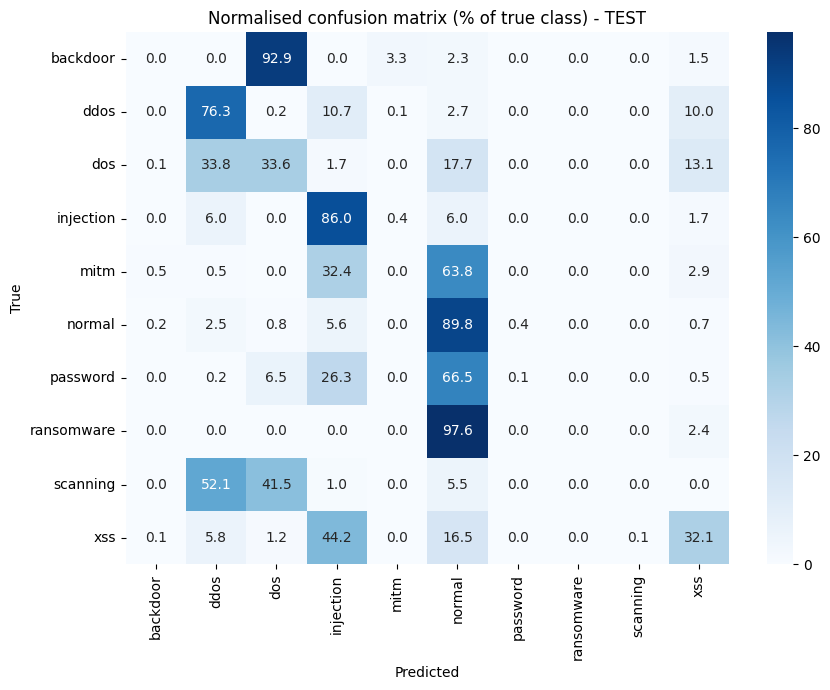


Saved: fedprox_adpmeta_recordDP_eps8.0_per_round.csv, _per_round_per_attack.csv, _final_test.csv, _final_test_per_attack.csv, .json, _best.pt


/tmp/ipykernel_48/2365761691.py:244: ResourceWarning: unclosed file <_io.TextIOWrapper name='fedprox_adpmeta_recordDP_eps8.0.json' mode='w' encoding='utf-8'>
  json.dump({"run": RUN_NAME, "dp_level": DP_LEVEL, "eps_budget": EPS_BUDGET, "final_epsilon": eps_prev, "delta": DELTA,


In [28]:
# =====================================================================================
# BLOCK 18 (FINAL): FedProx + ADP-Meta + Differential Privacy - ONE model
#   20 rounds | all 15 clients every round | DDQN detector (reward-only) | REINFORCE ADP-Meta controller
#   Per round  : validation accuracy, macro P/R/F1, FAR, DR, epsilon + P/R/F1 for EVERY attack class
#   At the end : TEST accuracy, precision, recall, F1 (macro + weighted + per attack), confusion matrix, figures
# Replaces the old Blocks 18, 18B and 19.
# Improvements locked from validation tests: #1 all training data per client (Block 16, D9),
#   #2 smaller DDQN network for private training (D10). Server EMA was tested in D10 and NOT used (it was worse).
# =====================================================================================
import copy, time, json
from opacus.accountants import RDPAccountant
from opacus.accountants.utils import get_noise_multiplier

# ------------------------------ settings ------------------------------
DP_LEVEL    = "record"     # "record" = record-level DP-SGD on each client (per-record clipping + noise)  <- learns
                           # "client" = client-level local DP (clip + noise each client's update before sending)
EPS_BUDGET  = 8.0          # total privacy budget (epsilon), delta below
DELTA       = 1e-5
ROUNDS      = 20
CLIENT_FRAC = 1.0          # all 15 clients participate every round
MU          = 0.01         # FedProx proximal coefficient
LAMBDA      = 1.0          # privacy-cost weight in the ADP-Meta reward
LEVEL_MULTS = (0.8, 0.9, 1.0, 1.2, 1.5)   # ADP-Meta actions: multiplier on the calibrated noise
CL_LOCAL_EPOCHS, CL_CLIP = 2, 1.0          # client-level DP settings
RL_STEPS, RL_BATCH, RL_LR = 400, 256, 1e-3 # record-level DP settings (chosen on validation, diagnostics D4-D8)
RUN_NAME = f"fedprox_adpmeta_{DP_LEVEL}DP_eps{EPS_BUDGET}"
assert DP_LEVEL in ("client", "record")
print(f"Run: {RUN_NAME} | {ROUNDS} rounds | {NUM_CLIENTS} clients/round x{CLIENT_FRAC} | FedProx mu={MU}")

# ------------------------------ smaller DDQN network for private training (suggestion #2, D10) ------------------------------
class SmallQNetwork(nn.Module):
    def __init__(self, input_dim, action_dim):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, 64), nn.LayerNorm(64), nn.ReLU(),
            nn.Linear(64, 32),        nn.LayerNorm(32), nn.ReLU())
        self.q_head = nn.Linear(32, action_dim)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.kaiming_normal_(m.weight, nonlinearity="relu"); nn.init.zeros_(m.bias)
    def forward(self, x, mode="q_value"):
        return self.q_head(self.feature_extractor(x))

class SmallDDQN(DDQN):                       # identical DDQN logic (reward, TD update, target net), smaller network
    def __init__(self, *args, lr=1e-3, **kwargs):
        super().__init__(*args, lr=lr, **kwargs)
        self.online_net = SmallQNetwork(input_dim, action_dim).to(self.device)
        self.target_net = SmallQNetwork(input_dim, action_dim).to(self.device)
        self.target_net.load_state_dict(self.online_net.state_dict()); self.target_net.eval()
        self.optimizer = optim.Adam(self.online_net.parameters(), lr=lr)

# ------------------------------ helpers ------------------------------
def prf_from_cm(cm):
    cm = np.array(cm, dtype=float); tp = np.diag(cm)
    p  = np.divide(tp, cm.sum(0), out=np.zeros_like(tp), where=cm.sum(0) > 0)
    r  = np.divide(tp, cm.sum(1), out=np.zeros_like(tp), where=cm.sum(1) > 0)
    f1 = np.divide(2 * p * r, p + r, out=np.zeros_like(tp), where=(p + r) > 0)
    return p, r, f1, cm.sum(1)

def per_sample_grad_norms(agent, X, y, n=1024):          # used only to pick C for record-level DP (validation data)
    net = agent.online_net; net.train()
    idx = np.random.default_rng(SEED).choice(len(y), size=min(n, len(y)), replace=False)
    x  = torch.as_tensor(X[idx], device=device); yy = torch.as_tensor(y[idx], device=device)
    a  = agent.act(x); r = agent.reward(a, yy)
    params  = {k: v.detach() for k, v in net.named_parameters()}
    buffers = {k: v.detach() for k, v in net.named_buffers()}
    def loss_fn(p, b, xi, ai, ri):
        qv = functional_call(net, (p, b), (xi.unsqueeze(0),)).squeeze(0)
        return F.smooth_l1_loss(qv.gather(0, ai.unsqueeze(0)).squeeze(0), ri)
    g = vmap(grad(loss_fn), in_dims=(None, None, 0, 0, 0), randomness="different")(params, buffers, x, a, r)
    return torch.sqrt(sum(gi.reshape(len(idx), -1).pow(2).sum(1) for gi in g.values())).cpu().numpy()

class ClientLevelDPClient(FLClient):
    """Full DDQN local training, then clip the whole update and add Gaussian noise ON THE CLIENT."""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.accountant = RDPAccountant()
    def epsilon_spent(self):
        return float(self.accountant.get_epsilon(delta=DELTA)) if self.accountant.history else 0.0
    def projected_epsilon(self, sigma):
        acc = copy.deepcopy(self.accountant); acc.step(noise_multiplier=sigma, sample_rate=1.0)
        return float(acc.get_epsilon(delta=DELTA))
    def private_fit(self, parameters, sigma):
        self.set_parameters(parameters)
        self.global_params = [p.detach().cpu().clone() for p in self.ddqn.online_net.parameters()]
        self.mu = MU
        self.local_train(CL_LOCAL_EPOCHS)
        with torch.no_grad():
            g_vec = torch.cat([g.view(-1) for g in self.global_params]).to(self.device)
            delta = self.ddqn.param_vector() - g_vec
            raw = float(torch.norm(delta))
            delta = delta * min(1.0, CL_CLIP / (raw + 1e-12))
            noise = torch.normal(0.0, sigma * CL_CLIP, size=delta.shape, device=self.device)
            assert float(torch.norm(noise)) > 0, "DP guard: noise not applied"
            delta = delta + noise
            self.accountant.step(noise_multiplier=sigma, sample_rate=1.0)
            out, off = [], 0
            for g in self.global_params:
                n = g.numel(); out.append((g.to(self.device) + delta[off:off + n].view_as(g)).cpu()); off += n
        return out, len(self.train_loader.dataset), {"signal": min(raw, CL_CLIP), "noise": float(torch.norm(noise))}

class RecordLevelDPClient(DPClient):
    def projected_epsilon(self, sigma):
        acc = copy.deepcopy(self.accountant)
        for _ in range(RL_STEPS):
            acc.step(noise_multiplier=sigma, sample_rate=self.q)
        return float(acc.get_epsilon(delta=DELTA))
    def private_fit(self, parameters, sigma):
        p, n, _ = self.fit(parameters, {"noise_multiplier": sigma, "local_steps": RL_STEPS, "mu": MU})
        return p, n, {"signal": float("nan"), "noise": float("nan")}

# ------------------------------ build model + clients ------------------------------
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)
rng = np.random.default_rng(SEED)

if DP_LEVEL == "client":
    g = SmallDDQN(input_dim, action_dim, device, class_weights_dp)                       # full DDQN, gamma = 0.1
    loaders = [DataLoader(TensorDataset(torch.from_numpy(X_dp[ci]), torch.from_numpy(y_dp[ci]).long()),
                          batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(SEED + k))
               for k, ci in enumerate(dp_client_indices)]
    clients = [ClientLevelDPClient(SmallDDQN(input_dim, action_dim, device, class_weights_dp), loaders[k], device,
                                   model_name=f"Client{k+1}") for k in range(len(loaders))]
    s = get_noise_multiplier(target_epsilon=EPS_BUDGET, target_delta=DELTA, sample_rate=1.0, steps=ROUNDS, accountant="rdp")
    base_sigma = [s] * len(clients)
    clip_used = CL_CLIP
else:
    torch.manual_seed(SEED)
    _ag = SmallDDQN(input_dim, action_dim, device, class_weights_dp, gamma=0.0, lr=RL_LR)
    clip_used = float(np.median(per_sample_grad_norms(_ag, X_val, y_val))); del _ag
    g = SmallDDQN(input_dim, action_dim, device, class_weights_dp, gamma=0.0, lr=RL_LR)
    clients = [RecordLevelDPClient(SmallDDQN(input_dim, action_dim, device, class_weights_dp, gamma=0.0, lr=RL_LR),
                                   X_dp[ci], y_dp[ci], device, model_name=f"Client{k+1}",
                                   batch_size=RL_BATCH, clip_norm=clip_used, delta=DELTA)
               for k, ci in enumerate(dp_client_indices)]
    base_sigma = [get_noise_multiplier(target_epsilon=EPS_BUDGET, target_delta=DELTA, sample_rate=min(1.0, c.q),
                                       steps=ROUNDS * RL_STEPS, accountant="rdp") for c in clients]
print(f"DP={DP_LEVEL}-level | clip C={clip_used:.3f} | base sigma: median {np.median(base_sigma):.3f}")

controller = ADPMetaController(list(LEVEL_MULTS), device=device)

# ------------------------------ training: 20 rounds ------------------------------
round_rows, class_rows = [], []
best_acc, best_round, best_state = -1.0, 0, None
acc_prev, dacc_prev, eps_prev = evaluate_global(g, val_dataset).ids_metrics()["Accuracy"], 0.0, 0.0
t0 = time.time()

for r in range(1, ROUNDS + 1):
    state = [r / ROUNDS, acc_prev, dacc_prev, eps_prev / EPS_BUDGET]
    mult = controller.select(state)[1]
    active = rng.choice(len(clients), size=max(1, math.ceil(CLIENT_FRAC * len(clients))), replace=False)

    # pre-round budget check: no client may exceed EPS_BUDGET
    forced = False
    if max(clients[i].projected_epsilon(base_sigma[i] * mult) for i in active) > EPS_BUDGET:
        mult, forced = max(LEVEL_MULTS), True
        if max(clients[i].projected_epsilon(base_sigma[i] * mult) for i in active) > EPS_BUDGET:
            print(f"Round {r}: privacy budget would be exceeded - stopping before spending.")
            break

    gp = g.get_fl_parameters()
    params, sizes, mets = [], [], []
    for i in active:
        p, n, m = clients[i].private_fit(gp, base_sigma[i] * mult)
        params.append(p); sizes.append(n); mets.append(m)
    g.set_fl_parameters(weighted_average(params, sizes))                              # FedProx server step

    mval = evaluate_global(g, val_dataset)
    ids = mval.ids_metrics()
    P, R, F1, _ = prf_from_cm(mval.cm)
    eps_now = max(c.epsilon_spent() for c in clients)
    dacc = ids["Accuracy"] - acc_prev
    reward = dacc - LAMBDA * (eps_now - eps_prev) / EPS_BUDGET
    if not forced:
        controller.update(reward, r)

    round_rows.append({"round": r, "noise_mult": mult, "forced": forced, "epsilon": eps_now,
                       "Accuracy": ids["Accuracy"], "Macro_P": P.mean(), "Macro_R": R.mean(), "Macro_F1": F1.mean(),
                       "FAR": ids["IDS_FAR"], "DR": ids["IDS_DR"], "reward": reward})
    for c, name in enumerate(class_names):
        class_rows.append({"round": r, "class": name, "Precision": P[c], "Recall": R[c], "F1": F1[c]})

    print(f"Round {r:02d} | mult={mult:.2f}{'*' if forced else ''} | eps={eps_now:.3f}/{EPS_BUDGET} | "
          f"VAL Acc={100*ids['Accuracy']:.2f}% P={100*P.mean():.1f} R={100*R.mean():.1f} F1={100*F1.mean():.1f} | "
          f"FAR={100*ids['IDS_FAR']:.2f}% DR={100*ids['IDS_DR']:.2f}%")
    print("          per-attack F1: " + " | ".join(f"{n}={100*f:.0f}" for n, f in zip(class_names, F1)))
    if DP_LEVEL == "client":
        print(f"          ‖signal‖={np.mean([m['signal'] for m in mets]):.2f}  ‖noise‖={np.mean([m['noise'] for m in mets]):.1f}")

    if ids["Accuracy"] > best_acc:
        best_acc, best_round, best_state = ids["Accuracy"], r, [p.clone() for p in g.get_fl_parameters()]
    acc_prev, dacc_prev, eps_prev = ids["Accuracy"], dacc, eps_now

print(f"\nTraining time: {(time.time()-t0)/60:.1f} min | final epsilon = {eps_prev:.3f} (delta={DELTA})")

# ------------------------------ per-round figures (validation) ------------------------------
rdf = pd.DataFrame(round_rows); cdf = pd.DataFrame(class_rows)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for col, lbl in [("Accuracy", "Accuracy"), ("Macro_P", "Macro precision"), ("Macro_R", "Macro recall"), ("Macro_F1", "Macro F1")]:
    ax[0].plot(rdf["round"], 100 * rdf[col], marker="o", label=lbl)
ax[0].set_title("Validation metrics per round (%)"); ax[0].set_xlabel("Round"); ax[0].legend()
ax[1].plot(rdf["round"], 100 * rdf["FAR"], marker="o", label="FAR"); ax[1].plot(rdf["round"], 100 * rdf["DR"], marker="o", label="DR")
ax[1].set_title("IDS FAR / DR per round (%)"); ax[1].set_xlabel("Round"); ax[1].legend()
ax[2].plot(rdf["round"], rdf["epsilon"], marker="o", color="tab:red", label="epsilon spent")
ax[2].axhline(EPS_BUDGET, ls="--", color="gray", label="budget")
ax2 = ax[2].twinx(); ax2.step(rdf["round"], rdf["noise_mult"], where="mid", color="tab:green", label="ADP-Meta noise mult")
ax[2].set_title("Privacy spent + ADP-Meta choice"); ax[2].set_xlabel("Round"); ax[2].legend(loc="upper left"); ax2.legend(loc="lower right")
plt.tight_layout(); plt.show()

heat = cdf.pivot(index="class", columns="round", values="F1").reindex(class_names)
plt.figure(figsize=(14, 5))
sns.heatmap(100 * heat, annot=True, fmt=".0f", cmap="YlGnBu", cbar_kws={"label": "F1 %"})
plt.title("Per-attack F1 (%) on validation, every round"); plt.xlabel("Round"); plt.ylabel("")
plt.tight_layout(); plt.show()

# ------------------------------ final TEST evaluation (best-validation model, used once) ------------------------------
g.set_fl_parameters(best_state)
print(f"\nBest validation round: {best_round} (VAL Acc={100*best_acc:.2f}%)")
res = final_report(g, test_dataset, title=f"TEST - {RUN_NAME}")      # per-attack P/R/F1 + confusion matrix figure
P, R, F1, sup = prf_from_cm(res["cm"]); w = sup / sup.sum()

final = pd.DataFrame([{
    "Model": "FedProx + DDQN + ADP-Meta", "DP": f"{DP_LEVEL}-level", "Rounds": len(rdf), "Clients/round": len(active),
    "Accuracy %": round(100 * res["ids"]["Accuracy"], 2), "Macro Precision %": round(100 * P.mean(), 2),
    "Macro Recall %": round(100 * R.mean(), 2), "Macro F1 %": round(100 * F1.mean(), 2),
    "Weighted F1 %": round(100 * (F1 * w).sum(), 2), "FAR %": round(100 * res["ids"]["IDS_FAR"], 2),
    "DR %": round(100 * res["ids"]["IDS_DR"], 2), "epsilon": round(eps_prev, 3), "delta": DELTA}])
per_attack = pd.DataFrame({"Precision %": np.round(100 * P, 2), "Recall %": np.round(100 * R, 2),
                           "F1 %": np.round(100 * F1, 2), "Support": sup.astype(int)}, index=class_names)
print("\nFINAL TEST RESULT\n", final.T.to_string(header=False))
print("\nPER-ATTACK TEST RESULT\n", per_attack.to_string())

cmn = res["cm"] / res["cm"].sum(1, keepdims=True)
plt.figure(figsize=(9, 7))
sns.heatmap(100 * cmn, annot=True, fmt=".1f", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Normalised confusion matrix (% of true class) - TEST")
plt.tight_layout(); plt.show()

# ------------------------------ save ------------------------------
rdf.to_csv(f"{RUN_NAME}_per_round.csv", index=False)
cdf.to_csv(f"{RUN_NAME}_per_round_per_attack.csv", index=False)
final.to_csv(f"{RUN_NAME}_final_test.csv", index=False)
per_attack.to_csv(f"{RUN_NAME}_final_test_per_attack.csv")
torch.save(best_state, f"{RUN_NAME}_best.pt")
json.dump({"run": RUN_NAME, "dp_level": DP_LEVEL, "eps_budget": EPS_BUDGET, "final_epsilon": eps_prev, "delta": DELTA,
           "rounds": ROUNDS, "client_frac": CLIENT_FRAC, "mu": MU, "lambda": LAMBDA, "level_mults": list(LEVEL_MULTS),
           "clip_norm": clip_used, "base_sigma": base_sigma, "best_round": best_round, "seed": SEED,
           "controller": controller.history, "test": res["ids"], "confusion_matrix": res["cm"].tolist()},
          open(f"{RUN_NAME}.json", "w"), indent=2)
print(f"\nSaved: {RUN_NAME}_per_round.csv, _per_round_per_attack.csv, _final_test.csv, _final_test_per_attack.csv, .json, _best.pt")